# 01 · From a sequence matrix to spectral features

Start with the core idea, check the matrix algebra, then export a feature table.
Requires the **development checkout** of Protspect and matplotlib. Run cells in
order, edit the controls, and rerun downstream cells. No external data are needed.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftshift
from IPython.display import display
from protspect import SequenceSet, transform_sequence
from protspect.embeddings import b100, kidera_factors
%matplotlib inline

## The matrix view

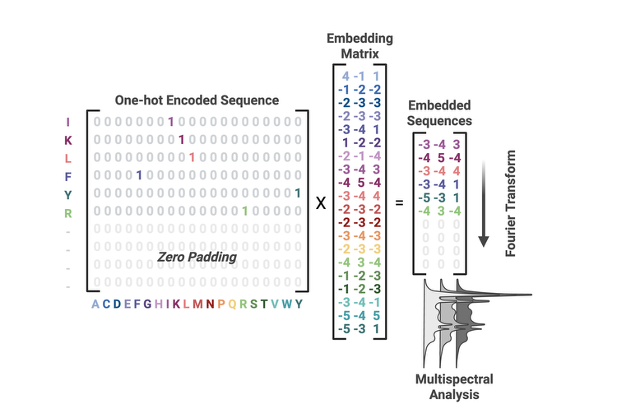

Project-provided illustration, reproduced unchanged. A one-hot **N × 20** matrix
multiplies a **20 × C** embedding to give **N × C** channel signals. Zero-padding
adds sequence rows, and Fourier acts along those rows (`axis=0`), separately for
each channel. The schematic has three channels; the code below uses the first
three actual Kidera factors, so its numbers need not match the drawing.

In [ ]:
SEQUENCE = "IKLFYR"
LENGTH = 16  # At least len(SEQUENCE); padding adds rows, not columns.
ALPHABET = "ACDEFGHIKLMNPQRSTVWY"
CHANNELS = ("KF1", "KF2", "KF3")
embedding = {name: kidera_factors()[name] for name in CHANNELS}

In [ ]:
N = len(SEQUENCE)
if LENGTH < N:
    raise ValueError("Choose LENGTH >= sequence length")
one_hot = np.eye(len(ALPHABET))[[ALPHABET.index(aa) for aa in SEQUENCE]]
E = np.array([[embedding[channel][aa] for channel in CHANNELS] for aa in ALPHABET])
X = one_hot @ E
padded_one_hot = np.pad(one_hot, ((0, LENGTH-N), (0, 0)))
padded_X = np.pad(X, ((0, LENGTH-N), (0, 0)))
np.testing.assert_allclose(padded_one_hot @ E, padded_X)
matrix_fft = fftshift(fft(padded_X, axis=0), axes=0)
result = transform_sequence(SEQUENCE, embedding, method="fourier", length=LENGTH)
library_fft = np.column_stack([result.coefficients[c] for c in CHANNELS])
np.testing.assert_allclose(matrix_fft, library_fft)
print("One-hot:", one_hot.shape, "Embedding:", E.shape,
      "Signal:", X.shape, "Padded signal / FFT:", library_fft.shape)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
axes[0].imshow(one_hot, aspect="auto", cmap="Blues", vmin=0, vmax=1)
axes[0].set(title="One-hot sequence", xlabel="Alphabet column", ylabel="Position")
axes[1].plot(padded_X)
axes[1].axvline(N-.5, color="grey", linestyle="--", label="Padding begins")
axes[1].set(title="Embedded, then zero-padded", xlabel="Sequence position", ylabel="Channel score")
axes[2].plot(result.coordinates["frequency"], np.abs(library_fft))
axes[2].set(title="Fourier magnitudes", xlabel="Cycles per residue", ylabel="Magnitude")
axes[2].legend(CHANNELS); plt.show()

## Build a sequence collection

BLOSUM100 supplies 20 channels and Kidera supplies ten. Both use the same API.
The primary export includes all unique Fourier bins, without a repeated closure
bin or an implicit dyadic selector. Center/normalize **real rows before padding**
when enabling those options.

In [ ]:
SEQUENCES = [SEQUENCE, SEQUENCE[::-1]]
for label, mapping in [("BLOSUM100", b100), ("Kidera", kidera_factors())]:
    dataset = SequenceSet(embedding=mapping, method="fourier", compute_cross_spectra=False)
    dataset.from_sequence_list(SEQUENCES, length=LENGTH,
        attributes={"id": ["original", "reversed"]})
    table = dataset.export_features("amplitude", attributes=["id"])
    print(label, table.shape)
    display(table.iloc[:, :8])

selected, names = result.features(("amplitude", "phase"),
    selector=lambda c: c["frequency"] >= 0)
print("Selected values:", selected.shape)
print("First names:", names[:4])

## What to try

Change the sequence, padded length, or channel subset. Compare raw versus
per-sequence centered/unit-energy signals using `center=True, normalization='energy'`
in `transform_sequence`; in that case preprocess X over real rows before comparing
with your own padded FFT. Magnitudes lose phase information; Fourier phase depends
on origin and alignment. More padding does not add residues or new independent
measurements. Continue with notebook 02 for other transforms and paired chains.